In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
import numpy as np
from IPython.core.pylabtools import figsize

col_names = [
    'sex', 'length', 'diameter', 'height',
    'whole_weight', 'shucked_weight', 'viscera_weight',
    'shell_weight', 'rings'
]


df = pd.read_csv('data.csv', header=None, names=col_names)

df['Sex'] = df['sex'].map({
    'M': 'Male', 'F': 'Female', 'I': 'Infant'
})

df = df.drop(columns=['sex'])

df.head()

,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings,Sex
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,Male
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,Male
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,Female
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,Male
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,Infant


In [5]:
sex_dist = ['Male', 'Infant', 'Female']

sex_counts = df['Sex'].value_counts().reindex(sex_dist)

dist_table = pd.DataFrame({
    'count': sex_counts,
    '%': (sex_counts / len(df) * 100).round(2)
})

dist_table.index.name = 'Category'
dist_table

,count,%
Category,,
Male,1528,36.58
Infant,1342,32.13
Female,1307,31.29


In [8]:
quant_cols = [
    'length', 'diameter', 'height',
    'whole_weight', 'shucked_weight',
    'viscera_weight', 'shell_weight', 'rings'
]

new_names = {
    'length': 'Length',
    'diameter': 'Diameter',
    'height': 'Height',
    'whole_weight': 'Whole weight',
    'shucked_weight': 'Shucked weight',
    'viscera_weight': 'Viscera weight',
    'shell_weight': 'Shell weight',
    'rings': 'Rings'
}

summary = df[quant_cols].describe().T
summary = summary[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary.index = [new_names[c] for c in summary.index]
summary.index.name = 'variable'

summary.round(3)

,mean,std,min,25%,50%,75%,max
variable,,,,,,,
Length,0.524,0.120,0.075,0.450,0.545,0.615,0.815
Diameter,0.408,0.099,0.055,0.350,0.425,0.480,0.650
Height,0.140,0.042,0.000,0.115,0.140,0.165,1.130
Whole weight,0.829,0.490,0.002,0.442,0.800,1.153,2.826
Shucked weight,0.359,0.222,0.001,0.186,0.336,0.502,1.488
Viscera weight,0.181,0.110,0.000,0.094,0.171,0.253,0.760
Shell weight,0.239,0.139,0.002,0.130,0.234,0.329,1.005
Rings,9.934,3.224,1.000,8.000,9.000,11.000,29.000


Text(0, 0.5, 'observation count')

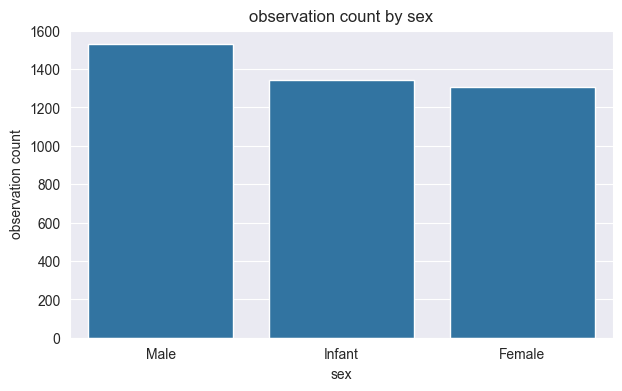

In [11]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Sex', order=sex_dist)
plt.title('observation count by sex')
plt.xlabel('sex')
plt.ylabel('observation count')

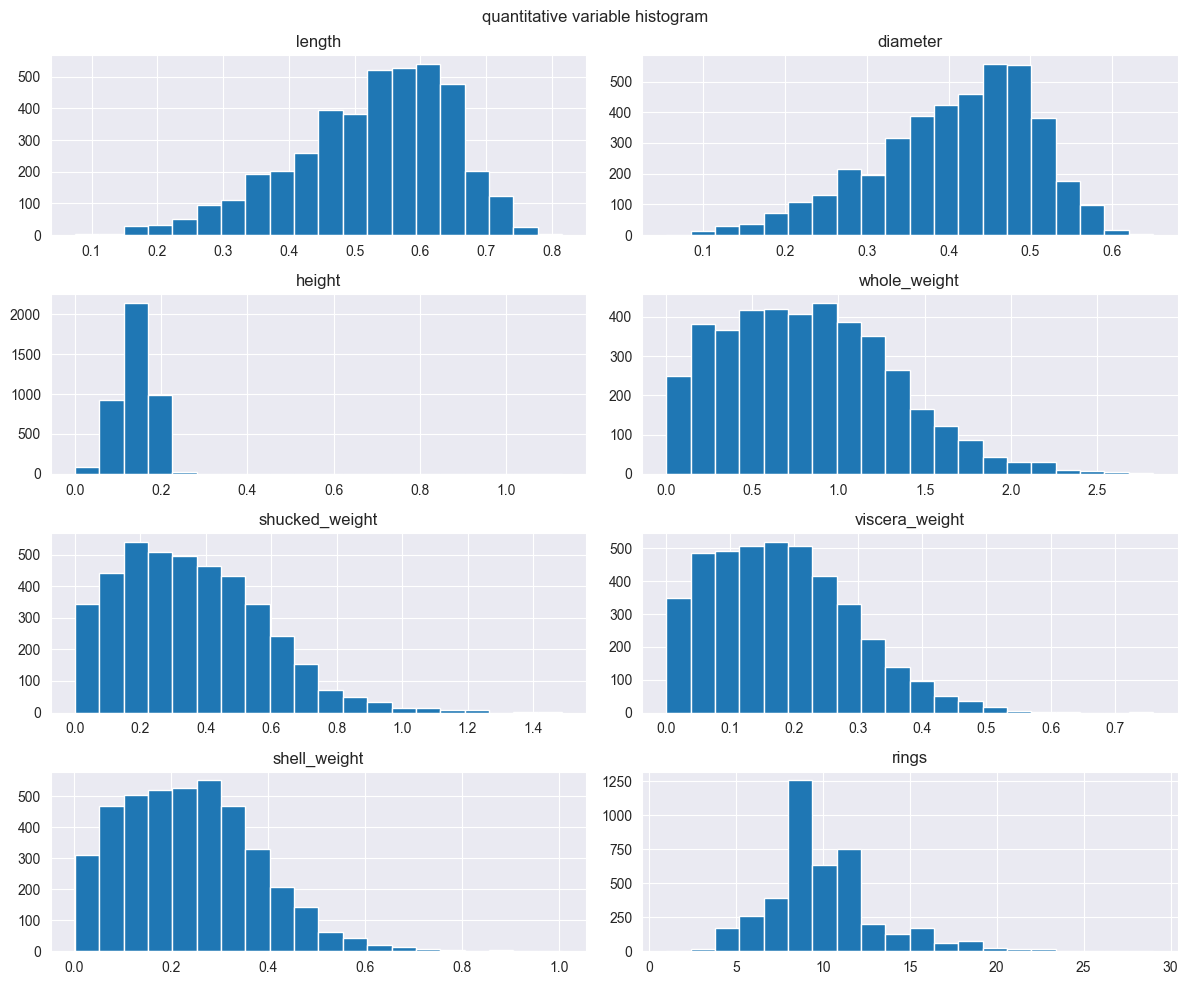

In [15]:
df[quant_cols].hist(
    figsize=(12, 10),
    bins = 20,
    layout = (4,2)
)

plt.suptitle('quantitative variable histogram')
plt.tight_layout()


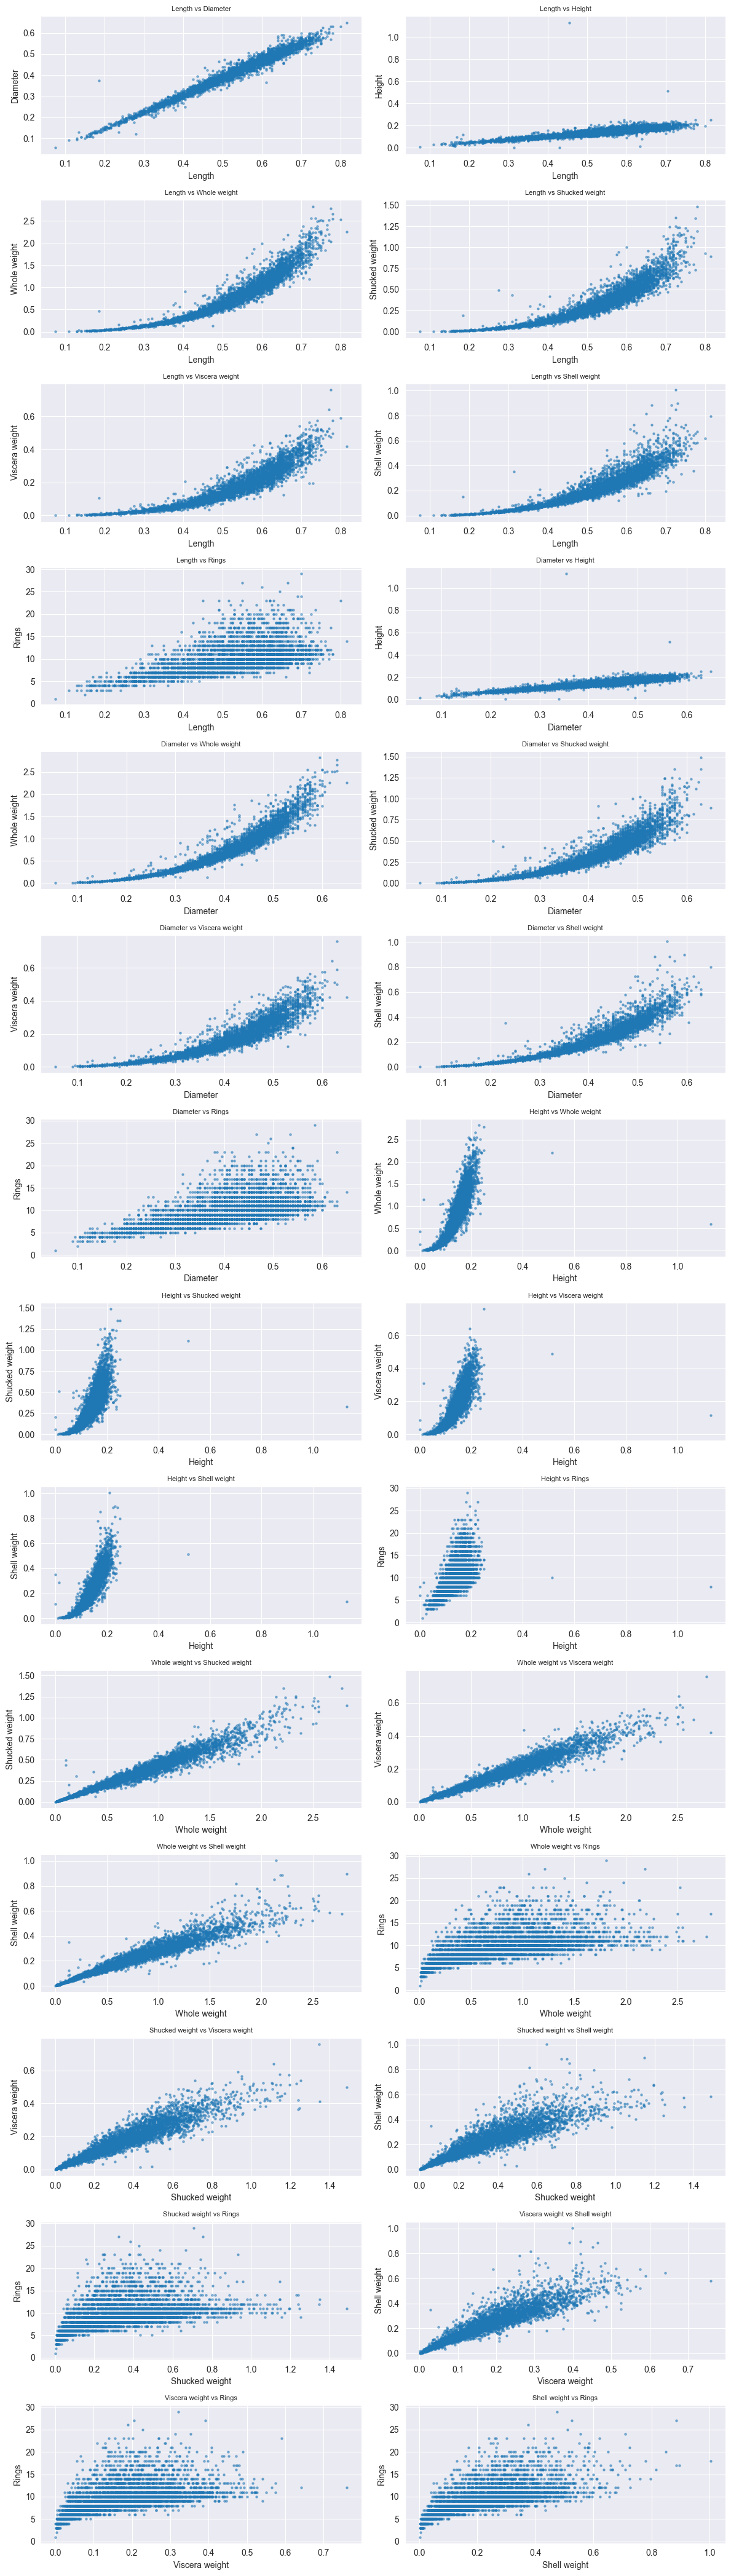

In [18]:
pairs = list(combinations(quant_cols, 2))

fig, axes = plt.subplots(14, 2, figsize=(12, 42))

for ax, (x, y) in zip(axes.flat, pairs):
    ax.scatter(df[x], df[y], s = 5, alpha = 0.5)
    ax.set_xlabel(new_names[x])
    ax.set_ylabel(new_names[y])
    ax.set_title(f'{new_names[x]} vs {new_names[y]}', fontsize=8)
plt.tight_layout()



In [21]:
corr = df[quant_cols].corr()

corr_display = corr.copy()
corr_display.index = [new_names[c] for c in corr_display.index]
corr_display.columns = [new_names[c] for c in corr_display.columns]

corr_display.round(3)

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
Length,1.000,0.987,0.828,0.925,0.898,0.903,0.898,0.557
Diameter,0.987,1.000,0.834,0.925,0.893,0.900,0.905,0.575
Height,0.828,0.834,1.000,0.819,0.775,0.798,0.817,0.557
Whole weight,0.925,0.925,0.819,1.000,0.969,0.966,0.955,0.540
Shucked weight,0.898,0.893,0.775,0.969,1.000,0.932,0.883,0.421
Viscera weight,0.903,0.900,0.798,0.966,0.932,1.000,0.908,0.504
Shell weight,0.898,0.905,0.817,0.955,0.883,0.908,1.000,0.628
Rings,0.557,0.575,0.557,0.540,0.421,0.504,0.628,1.000


Text(0.5, 1.0, 'linear correlation heatmap')

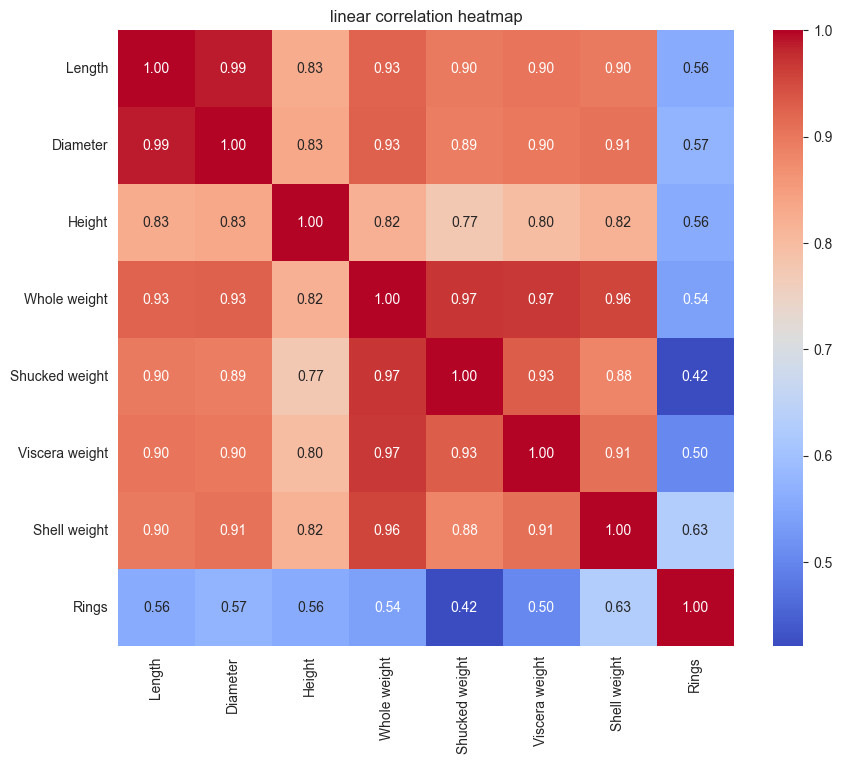

In [23]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_display,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True
)
plt.title('linear correlation heatmap')

r = 0.987


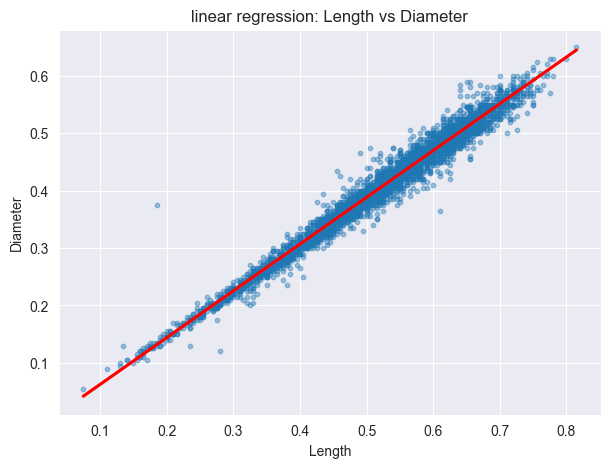

In [25]:
x_var = 'length'
y_var = 'diameter'

print('r =', round(corr.loc[x_var, y_var], 3))

plt.figure(figsize=(7, 5))
sns.regplot(
    data=df,
    x=x_var,
    y=y_var,
    scatter_kws={'s': 10, 'alpha': 0.4},
    line_kws={'color': 'red'}
)
plt.xlabel(new_names[x_var])
plt.ylabel(new_names[y_var])
plt.title(f'linear regression: {new_names[x_var]} vs {new_names[y_var]}')
plt.show()